# Compare a small metadata network: deduplicated Subset data

Can a small neural network improve on the spline using age, sex and anatomical site, the metadata recorded alongside each image? We also check how repeated training changes the result.

[05_metadata_models.ipynb](05_metadata_models.ipynb) supplies the fixed spline reference. Both methods use the same patient folds, meaning groups of patients, and are checked on people excluded from their own training.

The saved three-network average has average precision (AP) 0.0477 (pooled; 0.0596 mean-fold), versus 0.0492 (pooled; 0.0648 mean-fold) for the spline. Individual AP ranges from 0.0464 to 0.0486 pooled (0.0539 to 0.0588 mean-fold) as both the random seed and stopping group change. This does not justify replacing the spline on the main measure, AP. The network reads no image pixels.

For metric definitions, see the [short concept guide](../concepts.md).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [06_metadata_neural_network.ipynb](../Subset/06_metadata_neural_network.ipynb).

The clean workflow's primary ranking measure is **unweighted mean outer-fold AP**. The original pooled tables and figures are retained for presentation consistency and are explicitly secondary; their values are not interchangeable with mean-fold scores.

## Setup and data

Use the frozen `data/subset/processed/dedup_v1/dataset_manifest.json`, which retains 6,706 exact-copy-cleaned development records from the canonical CSV, with the project Python kernel. The notebook finds the project root from its current folder. The reserved test is not loaded.

Before the completed clean runs, fix one hidden layer with 32 units, 20% dropout, training settings, seeds 42, 142 and 242, and equal averaging. A seed makes random choices repeatable. Report every run and their average rather than selecting the highest score.

The reused patient folds have guided earlier comparisons, so these remain development results.


In [1]:
NOTEBOOK_STAGE = '06_metadata_neural_network'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss,
    roc_auc_score, roc_curve, precision_recall_curve,
)
from melanoma_detection.metadata_evaluation import probability_metrics, decision_metrics, calibration_bins
from melanoma_detection.dedup_notebook_metadata import (
    saved_metadata, metric_table, exploratory_cutoff, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
from melanoma_detection.dedup_notebook_metadata_templates import marginal_age_profile, metadata_patient_intervals
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
PROJECT_ROOT = ROOT
train = bundle["frame"].set_index("image_name").loc[frame.image_id].reset_index()
assert np.array_equal(train.patient_id, frame.patient_id)
assert np.array_equal(train.target, frame.target)
assert np.array_equal(train.fold, frame.fold)
assert train.groupby("patient_id").fold.nunique().eq(1).all()
assert train.image_name.is_unique and len(train) == 6706
assert int(train.target.sum()) == 127
FEATURE_COLUMNS = ["sex", "age_approx", "anatom_site_general_challenge"]
FEATURES = FEATURE_COLUMNS
DATA_PATH = ROOT / "data/subset/processed/dedup_v1/dataset_manifest.json"
TRAIN_FOLDS_PATH = DATA_PATH
REPORT_DIR = ROOT / "results/dedup_v1/clean_workflow/metadata_depth" / NOTEBOOK_STAGE
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = FIGURE_DIR
TABLES = METRICS = PREDICTIONS = REPORT_DIR
plt.rcdefaults()

BASE_SEEDS = [42, 142, 242]
spec = meta["core"]["specification"]["neural_network"]
epochs = pd.read_csv(meta["base"] / "epochs.csv")
history = pd.read_csv(meta["base"] / "history.csv")
print("Verified clean NN receipt:", (meta["base"] / "comparator_receipt.json").relative_to(ROOT))


# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 120})
ORIGINAL_EXPORT_DPI = 150


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

Verified clean NN receipt: results\dedup_v1\metadata\comparator_receipt.json


### 1. Check the inputs before training

Validate target text before conversion: only exact labels 0 (benign) and 1 (malignant) are accepted. Otherwise rounding or integer conversion could hide a bad value such as `1.5`. Each image must occur once, every patient must stay in one fold, and each fold must contain both classes.

Missing age is filled with the training median. Missing sex or site gets a fixed `Missing` label. Category columns are learned separately within training, keeping evaluation patients outside preprocessing.


In [2]:

print(f"Manifest: {DATA_PATH.relative_to(ROOT)}")
print(f"Dataset identity: {bundle['identity']['dataset_identity']}")
print(f"Images: {len(train):,}; patients: {train.patient_id.nunique():,}")
print(f"Malignant images: {int(train.target.sum()):,} ({train.target.mean():.2%})")
print(f"Malignant patients: {train.loc[train.target.eq(1), 'patient_id'].nunique():,}")
print("Original patient folds retained; reserved test not loaded.")

for fold, rows in train.groupby("fold"):
    assert rows.target.nunique() == 2
display(train.groupby("fold").agg(images=("target", "size"), patients=("patient_id", "nunique"), malignant_images=("target", "sum")))


Manifest: data\subset\processed\dedup_v1\dataset_manifest.json
Dataset identity: 0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae9f9eb7e57825b04af1
Images: 6,706; patients: 422
Malignant images: 127 (1.89%)
Malignant patients: 88
Original patient folds retained; reserved test not loaded.


,images,patients,malignant_images
fold,,,
0,1344,84,24
1,1366,84,26
2,1328,87,26
3,1371,82,25
4,1297,85,26


## How the network is trained

### Use a small network for tabular information

Turn age, sex and site into numerical inputs. Age uses the training median for missing values and training-based scaling. One-hot encoding gives each category a yes/no column. These are a short list of numbers, rather than image pixels, so the network learns from scratch.

Its hidden layer has 32 units, each combining the inputs with learned weights. ReLU keeps positive activations and replaces negative ones with zero, allowing flexible relationships. The final sigmoid maps the output to [0,1]. This is a probability estimate; calibration, agreement with observed rates, still needs checking.

Dropout masks 20% of hidden activations during training and is disabled when predicting. Weight decay discourages large weights. These limit overfitting, learning details that fail on new patients. With 422 patients and only 127 malignant images, a small fixed network is a cautious comparison, rather than a claim of the best design.

### Choose training length without scoring patients

An epoch is one pass through training records. Binary cross-entropy measures probability error; smaller is better.

For each outer fold and run:

1. Set aside the outer patients for scoring.
2. Use one of the four remaining folds to choose the best epoch. Fit preprocessing and the network on the other three.
3. Start fresh with the same seed, refit preprocessing on all four training folds, and train for that epoch count.
4. Predict the outer fold once. Repeat until each image has one held-out prediction per run, called out-of-fold (OOF) prediction.

The stopping fold follows `(outer fold + 1 + run index) % 5`. Stop after 12 epochs without meaningful improvement once 10 epochs have been attempted, or at 100 epochs. The selected best earlier epoch can be below 10. Outer labels never choose it.

### Repeat a fixed procedure three times

Initial weights, batch order and dropout are random. The stopping group also changes across runs, so their spread reflects both choices together. All runs reuse the same patients: their standard deviation describes training variation, not a confidence interval for new-patient performance. Keep every run and their equal average. Training gives malignant cases no extra loss weight.


In [3]:

display(pd.DataFrame([{"Input": "Age", "Saved transformation": "Training-median imputation then standard scaling"},
    {"Input": "Sex/site", "Saved transformation": "Fixed Missing label; training one-hot categories; unknown ignored"}]))
display(pd.DataFrame([spec]).T)


,Input,Saved transformation
0,Age,Training-median imputation then standard scaling
1,Sex/site,Fixed Missing label; training one-hot categori...


,0
base_seeds,"[42, 142, 242]"
hidden_units,32
dropout,0.2
max_epochs,100
min_epochs,10
patience,12
minimum_improvement,0.00001
batch_size,128
learning_rate,0.001
weight_decay,0.001


In [4]:

display(epochs[["base_seed", "outer_fold", "training_seed", "stop_fold", "selected_epochs", "attempted_stopping_epochs", "stop_log_loss", "epoch_fit_patients", "epoch_stop_patients", "score_patients"]].round(5))
print("Saved stopping BCE chose duration; fresh saved outer refits used that duration.")


,base_seed,outer_fold,training_seed,stop_fold,selected_epochs,attempted_stopping_epochs,stop_log_loss,epoch_fit_patients,epoch_stop_patients,score_patients
0,42,0,42,1,20,32,0.09066,254,84,84
1,142,0,142,2,18,30,0.09231,251,87,84
2,242,0,242,3,40,52,0.08740,256,82,84
3,42,1,43,2,59,71,0.09108,251,87,84
4,142,1,143,3,26,38,0.08799,256,82,84
5,242,1,243,4,12,24,0.09566,253,85,84
6,42,2,44,3,59,71,0.08589,253,82,87
7,142,2,144,4,12,24,0.09734,250,85,87
8,242,2,244,0,29,41,0.08357,251,84,87
9,42,3,45,4,11,23,0.09738,255,85,82


Saved stopping BCE chose duration; fresh saved outer refits used that duration.


### 2. Verify the prescribed runs on five patient-held-out folds

The checks below explicitly enforce patient separation and exactly one prediction per image per run. Preprocessing is fitted again whenever the training patients change. The spline reference is fitted once per outer fold because its fixed procedure is deterministic and does not change across network seeds.

In [5]:

nn_oof = {seed: scores[f"nn_seed_{seed}"] for seed in BASE_SEEDS}
nn_mean, spline_oof = scores["metadata_nn_mean"], scores["spline_raw"]
assert np.allclose(np.column_stack(list(nn_oof.values())).mean(axis=1), nn_mean,
    rtol=2*np.finfo(np.float32).eps, atol=1e-8)
training_log = epochs.copy()
checks = []
for fold in range(5):
    members = pd.read_csv(meta["base"] / f"fold_{fold}/selection_memberships.csv")
    for seed, rows in members.groupby("base_seed"):
        fitting = set(rows.loc[rows.role.eq("epoch_fitting"), "patient_id"])
        stopping = set(rows.loc[rows.role.eq("epoch_stopping"), "patient_id"])
        scoring = set(rows.loc[rows.role.eq("outer_validation"), "patient_id"])
        assert fitting.isdisjoint(stopping) and (fitting | stopping).isdisjoint(scoring)
        checks.append({"outer_fold": fold, "base_seed": seed, "fitting_patients": len(fitting),
            "stopping_patients": len(stopping), "scoring_patients": len(scoring), "overlap": 0})
display(pd.DataFrame(checks))
print("All fifteen saved patient-separated NN runs verified; no retraining.")


,outer_fold,base_seed,fitting_patients,stopping_patients,scoring_patients,overlap
0,0,42,254,84,84,0
1,0,142,251,87,84,0
2,0,242,256,82,84,0
3,1,42,251,87,84,0
4,1,142,256,82,84,0
5,1,242,253,85,84,0
6,2,42,253,82,87,0
7,2,142,250,85,87,0
8,2,242,251,84,87,0
9,3,42,255,85,82,0


All fifteen saved patient-separated NN runs verified; no retraining.


### 3. Read the performance and variation comparison

The original chart pools held-out predictions from all five outer folds. Its format, colour meaning and annotations are retained here; the added mean-fold table is primary for the clean workflow. Average precision (AP), the primary ranking measure (mean-fold aggregation in this clean workflow), rewards concentrating malignant images near the top of the ranking. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance. Higher is better for both. Brier score measures squared probability error; lower is better, but a small value alone does not establish accurate risks.

In the charts, the horizontal axis lists models and runs: blue spline, orange individual networks, dark-grey average. The vertical axis is AP on the left and ROC-AUC on the right. The dashed AP line is the malignant-image share; annotations give exact scores. No sampling uncertainty bars are shown.

The variation table describes the three individual runs, whose seed and stopping fold both change. Compare their spread and average with the spline. The network's higher ROC-AUC does not overturn its lower AP, the chosen primary measure.


,AP,ROC_AUC,Brier
model,,,
Spline logistic,0.04921,0.64283,0.01841
NN base seed 42,0.04672,0.66062,0.01839
NN base seed 142,0.04859,0.66933,0.01837
NN base seed 242,0.04640,0.67177,0.01839
NN mean of all three,0.04768,0.66946,0.01837


,runs,mean,sample_std,minimum,maximum,range
metric,,,,,,
AP,3,0.04724,0.00118,0.04640,0.04859,0.00219
ROC_AUC,3,0.66724,0.00586,0.66062,0.67177,0.01114
Brier,3,0.01838,0.00001,0.01837,0.01839,0.00002


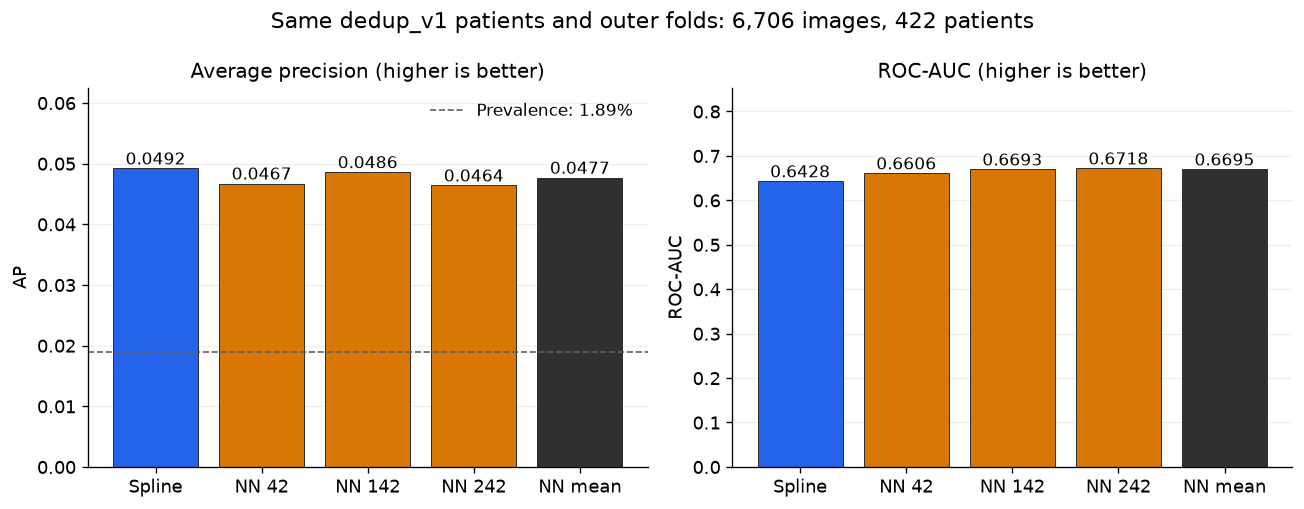

,scope,fold,average_precision,roc_auc,log_loss,brier
model,,,,,,
spline_raw,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842
nn_seed_42,mean_fold,NaN,0.05863,0.67325,0.09061,0.01840
nn_seed_142,mean_fold,NaN,0.05884,0.67409,0.09031,0.01838
nn_seed_242,mean_fold,NaN,0.05395,0.67562,0.09014,0.01840
metadata_nn_mean,mean_fold,NaN,0.05957,0.67669,0.09017,0.01838


In [6]:
labels = train.target.to_numpy()
model_scores = [('Spline logistic', spline_oof)]
model_scores += [(f'NN base seed {seed}', nn_oof[seed]) for seed in BASE_SEEDS]
model_scores += [('NN mean of all three', nn_mean)]
results = pd.DataFrame([
    {'model': name, 'AP': average_precision_score(labels, scores),
     'ROC_AUC': roc_auc_score(labels, scores),
     'Brier': brier_score_loss(labels, scores)}
    for name, scores in model_scores
])
display(results.set_index('model').round(5))
individual_results = results[results['model'].str.startswith('NN base seed')]
stability = pd.DataFrame([
    {'metric': metric, 'runs': len(BASE_SEEDS),
     'mean': individual_results[metric].mean(),
     'sample_std': individual_results[metric].std(ddof=1),
     'minimum': individual_results[metric].min(),
     'maximum': individual_results[metric].max(),
     'range': individual_results[metric].max() - individual_results[metric].min()}
    for metric in ['AP', 'ROC_AUC', 'Brier']
])
display(stability.set_index('metric').round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
short_labels = ['Spline', 'NN 42', 'NN 142', 'NN 242', 'NN mean']
colors = ['#2563EB', '#D97706', '#D97706', '#D97706', '#303030']
for axis, metric, title in zip(axes, ['AP', 'ROC_AUC'],
                             ['Average precision (higher is better)', 'ROC-AUC (higher is better)']):
    bars = axis.bar(short_labels, results[metric], color=colors, edgecolor='#303030', linewidth=0.6)
    for bar, value in zip(bars, results[metric]):
        axis.text(bar.get_x() + bar.get_width()/2, value, f'{value:.4f}',
                  ha='center', va='bottom', fontsize=10)
    if metric == 'AP':
        axis.axhline(labels.mean(), color='#606060', linestyle='--', linewidth=1,
                     label=f'Prevalence: {labels.mean():.2%}')
        axis.legend(loc='upper right', frameon=False, fontsize=10)
    axis.set_title(title, fontsize=12)
    axis.set_ylabel(metric.replace('_', '-'))
    axis.grid(axis='y', alpha=0.2)
    axis.set_axisbelow(True)
    axis.set_ylim(0, max(results[metric]) * 1.27)
fig.suptitle(f'Same dedup_v1 patients and outer folds: {len(train):,} images, '
             f'{train.patient_id.nunique():,} patients', fontsize=13)
fig.tight_layout()
FIGURE_PATH = FIGURE_DIR / 'metadata_nn_stability_dedup_v1.png'
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_PATH, bbox_inches='tight')
finish_figure(fig, 'nn_seed_stability')
display(metric_table(frame, scores, ["spline_raw", "nn_seed_42", "nn_seed_142", "nn_seed_242", "metadata_nn_mean"]).query("scope == 'mean_fold'").set_index("model").round(5))


### 4. Save predictions and run settings

Save one report row per retained image so later checks compare identical patients. SHA-256 fingerprints identify the frozen dataset manifest, retained IDs, original patient memberships, prediction bytes and training source code. The verified clean comparator receipt records preprocessing, network design, stopping and refit settings, package versions and every saved artifact. Fingerprints support traceability rather than proving correctness.

**Execution adaptation:** the original notebook trained and replaced its `metadata_nn_*` outputs. This clean notebook reads those separately completed clean fits and writes explanatory report copies under `results/dedup_v1/clean_workflow/metadata_depth/06_metadata_neural_network/`. Training receipts and predictions remain the authority. The `dedup_v1` filenames identify retained development data; no historical `d1` result is relabelled or overwritten. The reserved test remains outside these reports.

In [7]:

output = train[["image_name", "patient_id", "target", "fold"]].copy()
for seed in BASE_SEEDS:
    output[f"p_nn_seed_{seed}"] = nn_oof[seed]
output["p_nn_mean"], output["p_spline"] = nn_mean, spline_oof
paths = []
for report_name, report in [("matched_predictions", output), ("pooled_metrics", results),
    ("training_variability", stability), ("selected_epochs", epochs)]:
    paths.append(save_metadata_table(ROOT, NOTEBOOK_STAGE, report_name, report))
print("New explanatory report copies:")
for path in paths:
    print(path.relative_to(ROOT))
display(pd.DataFrame([{"dataset_identity": bundle["identity"]["dataset_identity"],
    "source_receipt": str((meta["base"] / "comparator_receipt.json").relative_to(ROOT)),
    "test_set_loaded": False, "training_on_notebook_execute": False}]))


New explanatory report copies:
results\dedup_v1\clean_workflow\metadata_depth\06_metadata_neural_network\matched_predictions.csv
results\dedup_v1\clean_workflow\metadata_depth\06_metadata_neural_network\pooled_metrics.csv
results\dedup_v1\clean_workflow\metadata_depth\06_metadata_neural_network\training_variability.csv
results\dedup_v1\clean_workflow\metadata_depth\06_metadata_neural_network\selected_epochs.csv


,dataset_identity,source_receipt,test_set_loaded,training_on_notebook_execute
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,results\dedup_v1\metadata\comparator_receipt.json,False,False


## Limitations

We test one small architecture, so this experiment cannot identify the best hidden-layer size, dropout rate or network design. Three fits check sensitivity to a few training choices. Because both the seed and stopping fold change together, their spread cannot isolate the effect of either choice.

All runs reuse the same patients. They are not three independent datasets, and the variability table is not a sampling confidence interval. This notebook does not establish calibrated probabilities or reliable performance across demographic groups; those checks belong in notebook 08.

The patient folds have guided earlier comparisons. Keeping outer patients outside fitting and epoch selection prevents direct leakage, but repeated model choices based on these folds can still make the chosen method look optimistic. Metadata also contains no lesion appearance. The reserved test is not used to evaluate these models, and performance on another hospital's patients or clinical safety is not established.


## Summary

The three-network average has AP 0.0477 pooled (0.0596 mean-fold) and ROC-AUC 0.6695 pooled (0.6767 mean-fold); the spline has AP 0.0492 pooled (0.0648 mean-fold) and ROC-AUC 0.6428 pooled (0.6556 mean-fold). Individual network AP ranges from 0.0464 to 0.0486 pooled; mean-fold AP ranges from 0.0539 to 0.0588.

Keep the spline as the primary metadata model because the prescribed average does not improve AP. Keep the network as an alternative; choosing the best individual run after seeing its score could favour a lucky result.

Next, [07_metadata_tuning.ipynb](07_metadata_tuning.ipynb) checks model settings and [08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) adds patient-based intervals, calibration and subgroup checks. Freeze the complete method before final testing.


## Additional deduplicated-workflow diagnostics

The complete original section sequence above is retained as the template. The following clearly labelled additions document clean artifact verification, training support and explanatory diagnostics that were not figures in the original. They remain secondary development evidence and do not select another model or cutoff.

In [8]:

import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))


,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


### Added diagnostic: 3. Read all fifteen stopping trajectories

Each panel is one outer-training pool. Solid lines show fitting BCE and dashed lines show patient-disjoint stopping BCE for each seed. Vertical dotted lines mark selected durations. Falling fitting loss with flat or rising stopping loss can indicate overfitting; these are training-only selection diagnostics, not outer-fold performance.

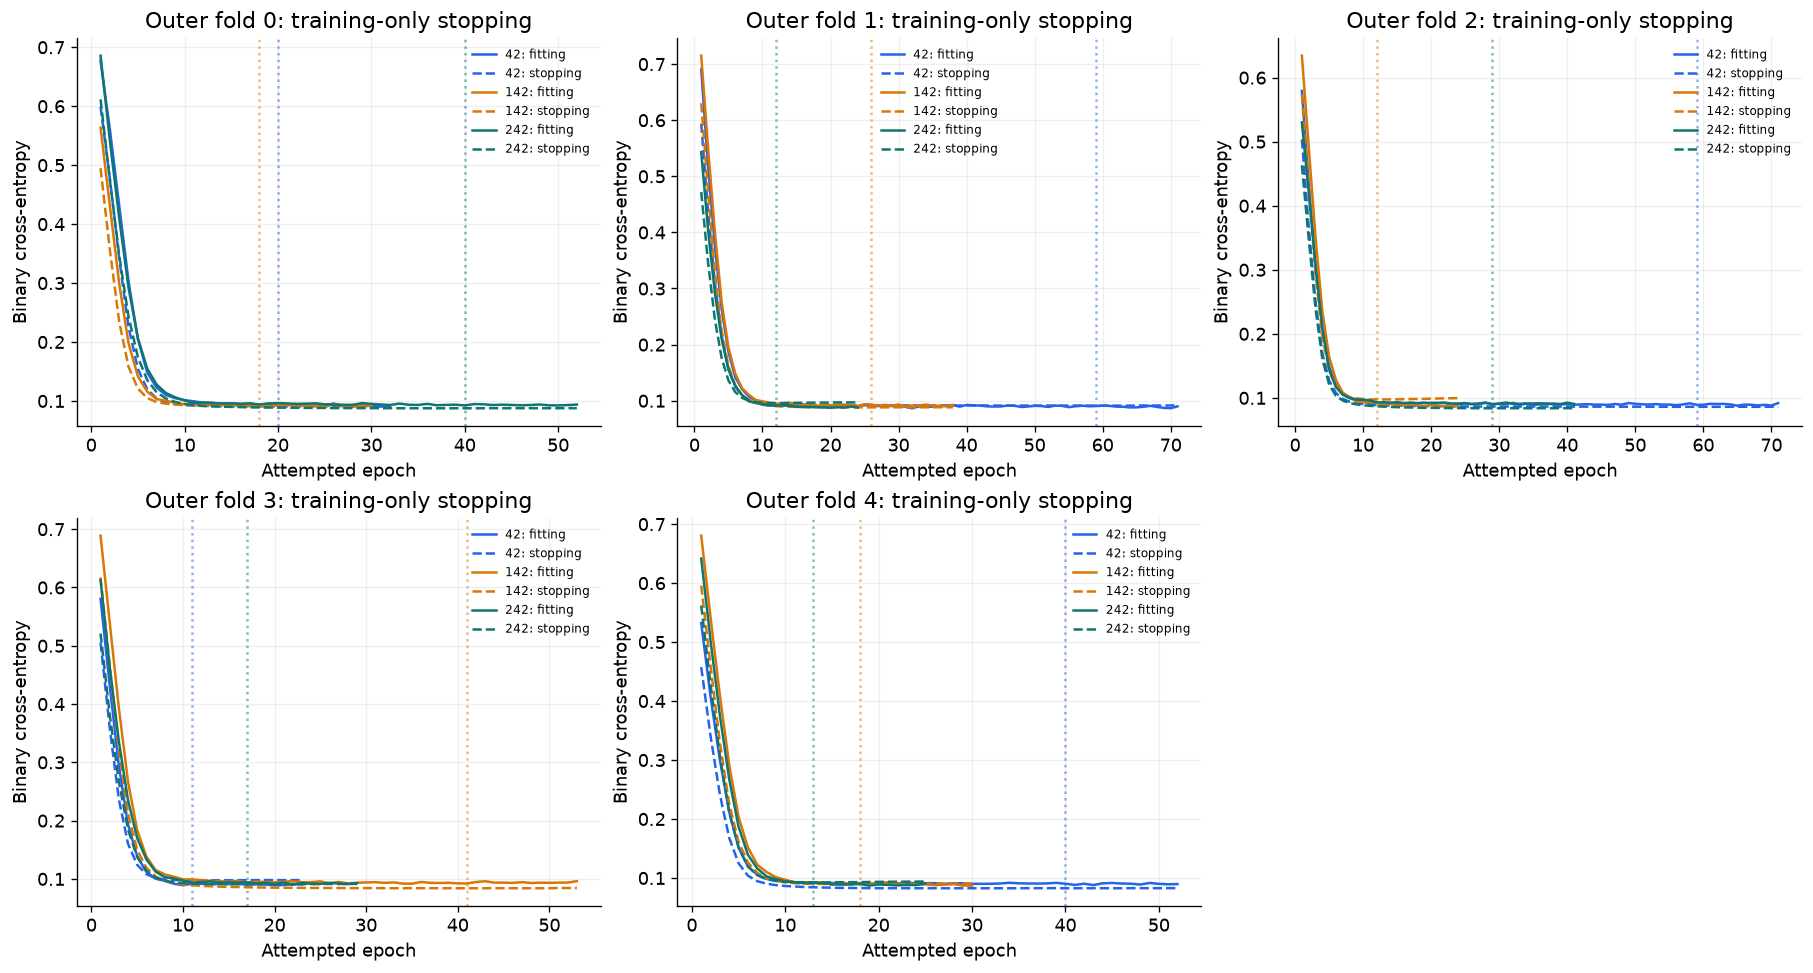

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for fold, ax in enumerate(axes.flat[:5]):
    for index, seed in enumerate([42, 142, 242]):
        rows = history.loc[history.outer_fold.eq(fold) & history.base_seed.eq(seed) & history.phase.eq("stopping")]
        selected = int(epochs.loc[epochs.outer_fold.eq(fold) & epochs.base_seed.eq(seed), "selected_epochs"].iloc[0])
        ax.plot(rows.epoch, rows.fit_bce, color=COLORS[index], label=f"{seed}: fitting")
        ax.plot(rows.epoch, rows.stop_bce, "--", color=COLORS[index], label=f"{seed}: stopping")
        ax.axvline(selected, linestyle=":", color=COLORS[index], alpha=.5)
    ax.set(title=f"Outer fold {fold}: training-only stopping", xlabel="Attempted epoch", ylabel="Binary cross-entropy")
    ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=7)
axes.flat[5].axis("off")
finish_figure(fig, "nn_fifteen_stopping_trajectories")

### Added diagnostic: 4. Read the fresh refit histories and selected durations

The outer refit runs for its selected duration using all four training folds. Only fitting BCE is available here; it must not be interpreted as validation performance. The duration table makes the workload and stopping-fold sensitivity visible without selecting a new duration from these plots.

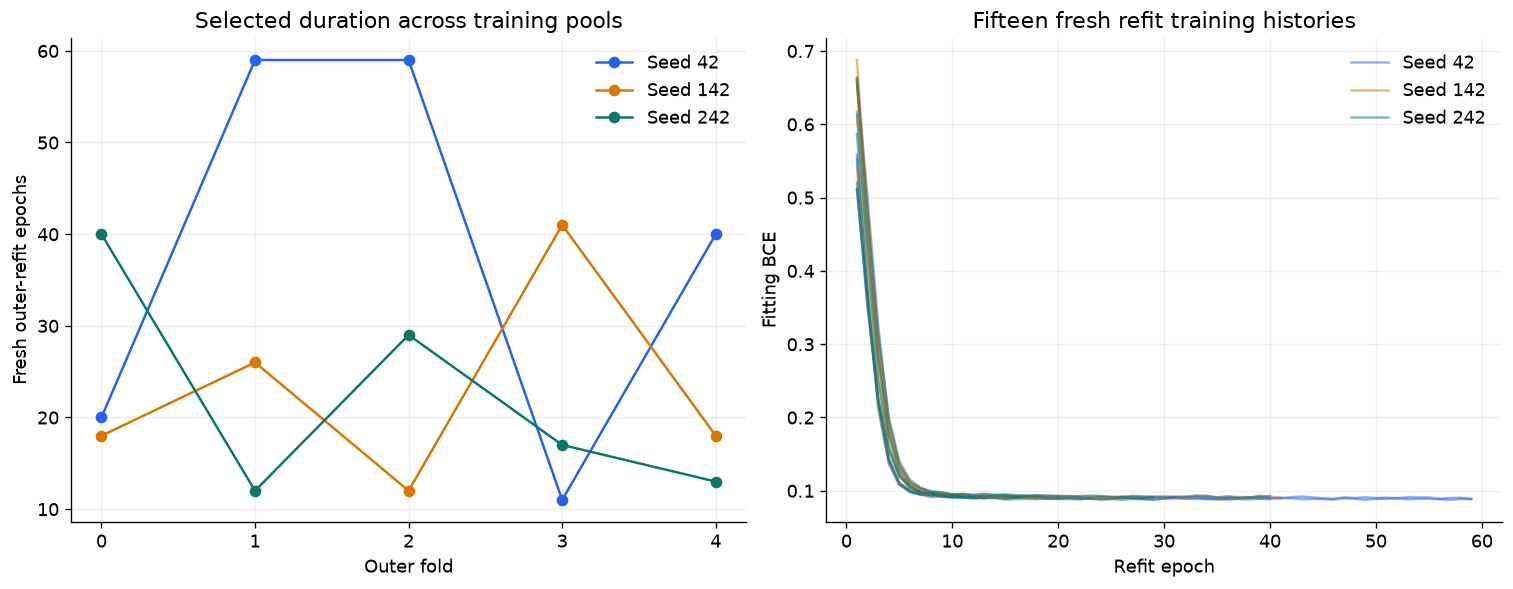

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout="constrained")
for index, seed in enumerate([42, 142, 242]):
    rows = epochs.loc[epochs.base_seed.eq(seed)]
    axes[0].plot(rows.outer_fold, rows.selected_epochs, "o-", color=COLORS[index], label=f"Seed {seed}")
    for fold in range(5):
        line = history.loc[history.base_seed.eq(seed) & history.outer_fold.eq(fold) & history.phase.eq("outer_refit")]
        axes[1].plot(line.epoch, line.fit_bce, color=COLORS[index], alpha=.5, label=f"Seed {seed}" if fold == 0 else None)
axes[0].set(title="Selected duration across training pools", xlabel="Outer fold", ylabel="Fresh outer-refit epochs", xticks=range(5))
axes[1].set(title="Fifteen fresh refit training histories", xlabel="Refit epoch", ylabel="Fitting BCE")
for ax in axes: ax.grid(alpha=.2); ax.legend(frameon=False)
finish_figure(fig, "nn_selected_epochs_and_refits")

### Added diagnostic: 6. Verify the ensemble and inspect seed disagreement

The ensemble uses the equal mean of all three seed probabilities. Verify it within the float32 arithmetic precision of the saved NN inference and report the small numerical difference after CSV loading. Between-seed score spread is an exploratory stability diagnostic; it is not the later image MC-dropout uncertainty measure. Listed images are development review examples, not automatic exclusions or new training rules.

,Maximum float64 reconstruction difference,Saved inference arithmetic
0,1.166667e-08,float32 equal mean; original retained scores p...


,image_id,patient_id,fold,target,ensemble_score,seed_score_sd
2068,ISIC_3119175,IP_1210062,2,0,0.12672,0.06028
4162,ISIC_6159454,IP_1210062,2,0,0.12672,0.06028
2303,ISIC_3445468,IP_6215369,2,0,0.12092,0.05218
2852,ISIC_4263017,IP_0391953,2,0,0.12092,0.05218
1506,ISIC_2301843,IP_8326844,1,0,0.11975,0.04965
2608,ISIC_3876274,IP_3846489,1,0,0.10449,0.04042
3298,ISIC_4954740,IP_0444327,1,0,0.10449,0.04042
1440,ISIC_2215830,IP_7716159,1,0,0.09784,0.03756
1508,ISIC_2306349,IP_9092661,1,1,0.09784,0.03756
3052,ISIC_4565629,IP_3370847,1,0,0.09486,0.03731


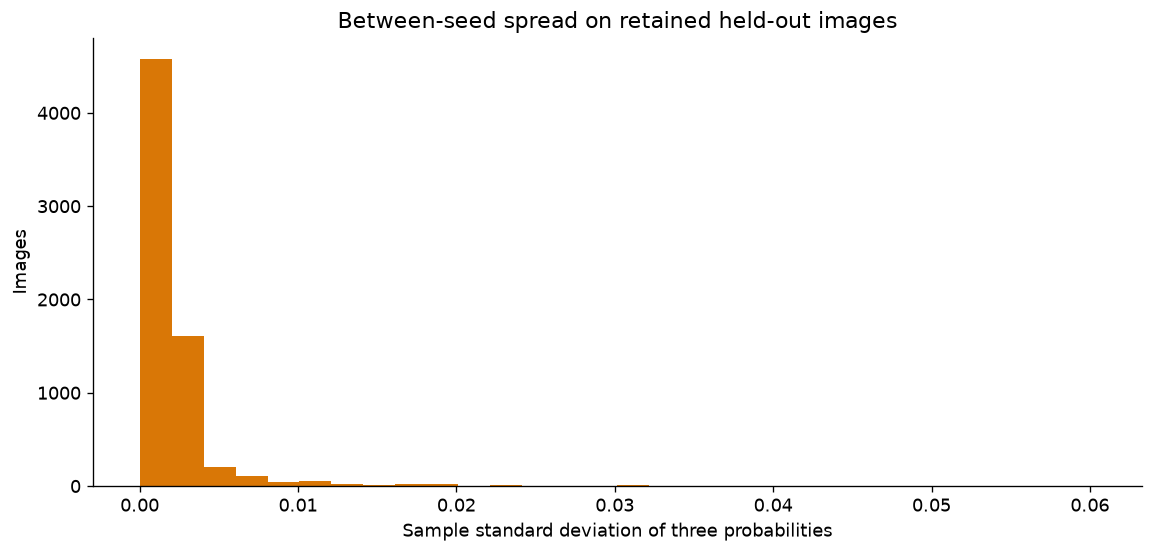

In [11]:
seed_values = np.column_stack([scores[f"nn_seed_{seed}"] for seed in [42, 142, 242]])
mean_difference = float(np.max(np.abs(seed_values.mean(axis=1) - scores["metadata_nn_mean"])))
assert np.allclose(seed_values.mean(axis=1), scores["metadata_nn_mean"], rtol=2*np.finfo(np.float32).eps, atol=1e-8)
display(pd.DataFrame([{"Maximum float64 reconstruction difference": mean_difference, "Saved inference arithmetic": "float32 equal mean; original retained scores preserved"}]))
review = frame[["image_id", "patient_id", "fold", "target"]].copy()
review["ensemble_score"] = scores["metadata_nn_mean"]
review["seed_score_sd"] = seed_values.std(axis=1, ddof=1)
display(review.sort_values(["seed_score_sd", "image_id"], ascending=[False, True]).head(12).round(5))
fig, ax = plt.subplots(figsize=(9.5, 4.5), layout="constrained")
ax.hist(review.seed_score_sd, bins=30, color="#d97706")
ax.set(title="Between-seed spread on retained held-out images", xlabel="Sample standard deviation of three probabilities", ylabel="Images")
finish_figure(fig, "nn_between_seed_disagreement")

### Added diagnostic: 7. Read held-out curves and the supported conclusion

Read the NN and spline at a common recall; a higher AP is not a calibrated risk or a clinical decision rule. Notebook 08 supplies the paired whole-patient interval for NN mean minus fixed spline. These curves and seed diagnostics do not justify replacing the primary model by whichever seed looks best.

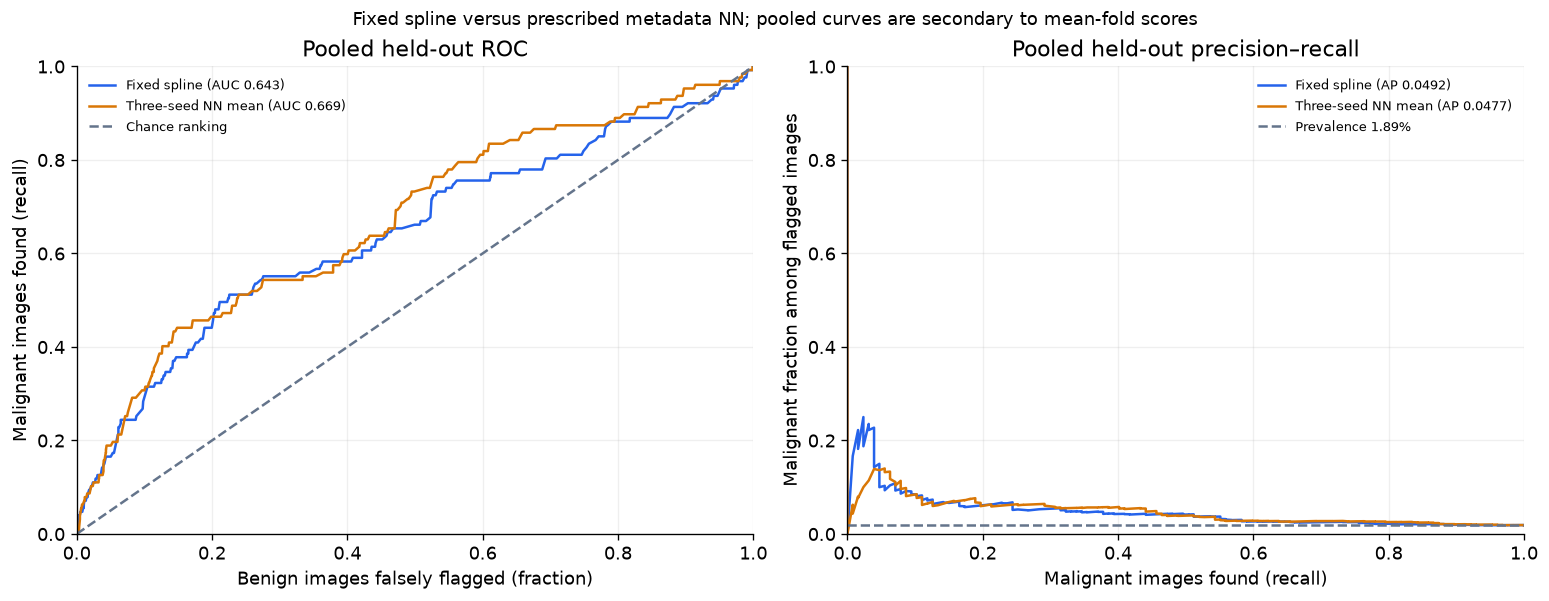

All three prescribed runs are included. Stopping and refit histories are complete; outer predictions remain held out by patient. Probability calibration, decision support and paired intervals follow in notebook 08.

In [12]:
finish_figure(curve_figure(frame, scores, ["spline_raw", "metadata_nn_mean"], "Fixed spline versus prescribed metadata NN"), "nn_spline_roc_pr")
display(Markdown("All three prescribed runs are included. Stopping and refit histories are complete; outer predictions remain held out by patient. Probability calibration, decision support and paired intervals follow in notebook 08."))